In [1]:
#--Importing packages--
import numpy as np
import random
import matplotlib.pyplot as plt
%matplotlib inline
import pandas as pd
import scipy.optimize as optimization

In [2]:
#--Importing the data frames--
coolMain_unclean = pd.read_csv('UltracoolSheetMain.csv') #Main sheet
coolProp_unclean = pd.read_csv('UltracoolSheet_FundamentalProperties.csv') #Fundamental Properties sheet

#--Filters--
#Filitering our NANs for the main data frame
d1f1 = coolMain_unclean[np.isnan(np.array(coolMain_unclean['age_singlevalue_gyr_formula'].values.astype(float))) == False]
d1f2 = d1f1[np.isnan(np.array(d1f1['K_MKO'].values.astype(float))) == False]
coolMain = d1f2[np.isnan(np.array(d1f2['J_MKO'].values.astype(float))) == False]
#Filtering out NANs for the fundemental properties data frame
d2f1 = coolProp_unclean[np.isnan(np.array(coolProp_unclean['teff_atmo'].values.astype(float))) == False]
coolProp = d2f1[np.isnan(np.array(d2f1['teff_evo'].values.astype(float))) == False]

#--Reading out Data--
#Arrays for each column I'll be using
age = np.array(coolMain['age_singlevalue_gyr_formula'].values.astype(float))
k_mko = np.array(coolMain['K_MKO'].values.astype(float))
j_mko = np.array(coolMain['J_MKO'].values.astype(float))
t_atmo = np.array(coolProp['teff_atmo'].values.astype(float))
t_evo = np.array(coolProp['teff_evo'].values.astype(float))
exoplanet = coolMain['exoplanet'].values.astype(str)
name_Main = coolMain['name'].values.astype(str)
name_Prop = coolProp['name'].values.astype(str)
#Empty arrays for each variable and each subgroup
#young age group
y_age = np.array([])
y_k = np.array([]) #k-band photometry
y_j = np.array([]) #j-band photometry
y_jk = np.array([])
y_atmo = np.array([]) #atmospheric temp
y_evo = np.array([]) #evolutionary temp
#Middle-aged group
m_age = np.array([])
m_k = np.array([])
m_j = np.array([])
m_jk = np.array([])
m_atmo = np.array([])
m_evo = np.array([])
#old age group
o_age = np.array([])
o_k = np.array([])
o_j = np.array([])
o_jk = np.array([])
o_atmo = np.array([])
o_evo = np.array([])
#All age groups
all_jk = np.array([])
all_atmo = np.array([])
all_evo = np.array([])
all_age = np.array([])

#--Organizing Data--
for i in range(len(name_Prop)):
  for f in range(len(name_Main)):
    if (name_Prop[i] == name_Main[f]): #When both data frames have an object with the same name (aka when the object is in both sheets)
      all_jk = np.append(all_jk, j_mko[f]-k_mko[f])
      all_atmo = np.append(all_atmo, t_atmo[i])
      all_evo = np.append(all_evo, t_evo[i])
      all_age = np.append(all_age, age[f])
      if (age[f] < 2): #when age is less than 2 Gyr (young age group)
        y_age = np.append(y_age, age[f])
        y_k = np.append(y_k, k_mko[f])
        y_j = np.append(y_j, j_mko[f])
        y_jk = np.append(y_jk, j_mko[f]-k_mko[f])
        y_atmo = np.append(y_atmo, t_atmo[i])
        y_evo = np.append(y_evo, t_evo[i])
      if (age[f] >=2) and (age[f] < 4): #When age is greater than 2 Gyr and less than 4 Gyr (middle-aged group)
        m_age = np.append(m_age, age[f])
        m_k = np.append(m_k, k_mko[f])
        m_j = np.append(m_j, j_mko[f])
        m_jk = np.append(m_jk, j_mko[f]-k_mko[f])
        m_atmo = np.append(m_atmo, t_atmo[i])
        m_evo = np.append(m_evo, t_evo[i])
      if (age[f] >= 4): #When age is greater than 4 Gyr (old age group)
        o_age = np.append(o_age, age[f])
        o_k = np.append(o_k, k_mko[f])
        o_j = np.append(o_j, j_mko[f])
        o_jk = np.append(o_jk, j_mko[f]-k_mko[f])
        o_atmo = np.append(o_atmo, t_atmo[i])
        o_evo = np.append(o_evo, t_evo[i])

print("Number of points in each group:\n")
print("Young group:", len(y_age), "      Middle-age group:", len(m_age), "      Old age group:", len(o_age), "      All:", len(all_jk))

Number of points in each group:

Young group: 196       Middle-age group: 783       Old age group: 61       All: 1040


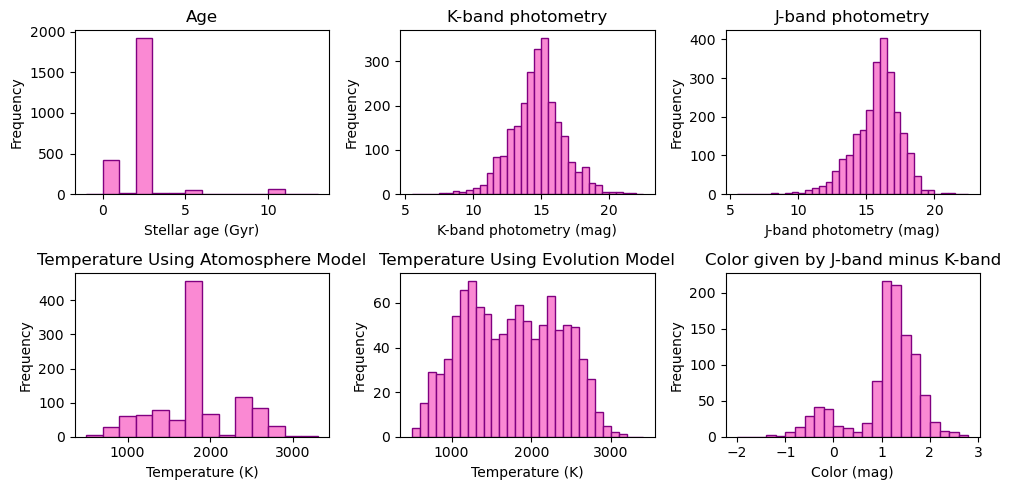

In [3]:
#--Histograms for all the data--
f, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(10, 5))

#Age
bins1 = np.arange(-1, 14, 1)
im1 = ax1.hist(age, edgecolor='purple', bins=bins1, color='#fa89d3')
ax1.set_title('Age')
ax1.set_xlabel('Stellar age (Gyr)')
ax1.set_ylabel('Frequency')

#K-band
bins2 = np.arange(5.5, 23, 0.5)
im2 = ax2.hist(k_mko, edgecolor='purple', bins=bins2, color='#fa89d3')
ax2.set_title('K-band photometry')
ax2.set_xlabel('K-band photometry (mag)')
ax2.set_ylabel('Frequency')

#J-band
bins3 = np.arange(5.5, 23, 0.5)
im3 = ax3.hist(j_mko, edgecolor='purple', bins=bins3, color='#fa89d3')
ax3.set_title('J-band photometry')
ax3.set_xlabel('J-band photometry (mag)')
ax3.set_ylabel('Frequency')

#Atmo Temp
bins4 = np.arange(500, 3500, 200)
im4 = ax4.hist(t_atmo, edgecolor='purple', bins=bins4, color='#fa89d3')
ax4.set_title('Temperature Using Atomosphere Model')
ax4.set_xlabel('Temperature (K)')
ax4.set_ylabel('Frequency')

#Evo Temp
bins5 = np.arange(500, 3500, 100) #or 200
im5 = ax5.hist(t_evo, edgecolor='purple', bins=bins5, color='#fa89d3')
ax5.set_title('Temperature Using Evolution Model')
ax5.set_xlabel('Temperature (K)')
ax5.set_ylabel('Frequency')

#Color
bins6 = np.arange(-2, 3, 0.2)
im6 = ax6.hist(all_jk, edgecolor='purple', bins=bins6, color='#fa89d3')
ax6.set_title('Color given by J-band minus K-band')
ax6.set_xlabel('Color (mag)')
ax6.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

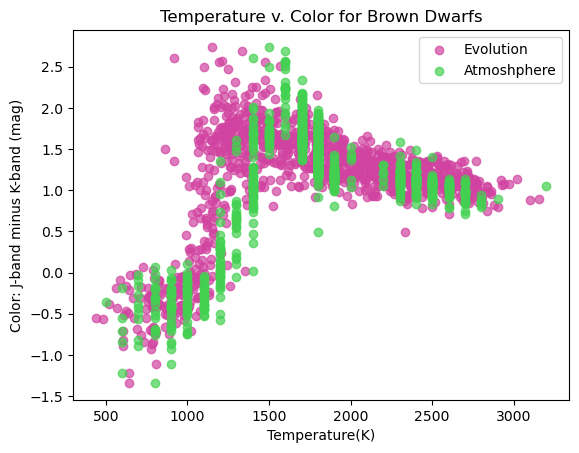

In [4]:
#--Scatter plot--
plt.scatter(all_evo, all_jk, color='#d143a0', alpha=0.7, label='Evolution') #!!Colors?!!
plt.scatter(all_atmo, all_jk, color='#43d151', alpha=0.7, label='Atmoshphere')
plt.title('Temperature v. Color for Brown Dwarfs')
plt.xlabel('Temperature(K)')
plt.ylabel('Color: J-band minus K-band (mag)')
plt.legend()
plt.show()

In [5]:
#--Quintic function for optimization--
def quintic(x,a,b,c,d,e,f):
  return a + b*x + c*x**2 + d*x**3 + e*x**4 + f*x**5

In [6]:
#--Curve fitting--

#Curve fit for all data
#Evolution
all_evo_sorted = np.arange(np.min(all_evo), np.max(all_evo), 0.1)
fit_all_evo = optimization.curve_fit(quintic, all_evo, all_jk)
allEvoA, allEvoB, allEvoC, allEvoD, allEvoE, allEvoF = fit_all_evo[0]
#Atmosphere
all_atmo_sorted = np.arange(np.min(all_atmo), np.max(all_atmo), 0.1)
fit_all_atmo = optimization.curve_fit(quintic, all_atmo, all_jk)
allAtmoA, allAtmoB, allAtmoC, allAtmoD, allAtmoE, allAtmoF = fit_all_atmo[0]

#Curve fit for young stars
#Evolution
y_evo_sorted = np.arange(np.min(y_evo), np.max(y_evo), 0.1)
fit_y_evo = optimization.curve_fit(quintic, y_evo, y_jk)
yEvoA, yEvoB, yEvoC, yEvoD, yEvoE, yEvoF = fit_y_evo[0]
#Atmosphere
y_atmo_sorted = np.arange(np.min(y_atmo), np.max(y_atmo), 0.1)
fit_y_atmo = optimization.curve_fit(quintic, y_atmo, y_jk)
yAtmoA, yAtmoB, yAtmoC, yAtmoD, yAtmoE, yAtmoF = fit_y_atmo[0]

#Curve fit for middle-age stars
#Evolution
m_evo_sorted = np.arange(np.min(m_evo), np.max(m_evo), 0.1)
fit_m_evo = optimization.curve_fit(quintic, m_evo, m_jk)
mEvoA, mEvoB, mEvoC, mEvoD, mEvoE, mEvoF = fit_m_evo[0]
#Atmosphere
m_atmo_sorted = np.arange(np.min(m_atmo), np.max(m_atmo), 0.1)
fit_m_atmo = optimization.curve_fit(quintic, m_atmo, m_jk)
mAtmoA, mAtmoB, mAtmoC, mAtmoD, mAtmoE, mAtmoF = fit_m_atmo[0]

#Curve fit for old stars
#Evolution
o_evo_sorted = np.arange(np.min(o_evo), np.max(o_evo), 0.1)
fit_o_evo = optimization.curve_fit(quintic, o_evo, o_jk)
oEvoA, oEvoB, oEvoC, oEvoD, oEvoE, oEvoF = fit_o_evo[0]
#Atmosphere
o_atmo_sorted = np.arange(np.min(o_atmo), np.max(o_atmo), 0.1)
fit_o_atmo = optimization.curve_fit(quintic, o_atmo, o_jk)
oAtmoA, oAtmoB, oAtmoC, oAtmoD, oAtmoE, oAtmoF = fit_o_atmo[0]

In [ ]:
#Function to find r squared values
def r_squared(x, y, aCo,bCo,cCo,dCo,eCo,fCo):
  y_predicted = quintic(x,aCo,bCo,cCo,dCo,eCo,fCo)
  r = 1-((np.sum((y-y_predicted)**2))/(np.sum((y-np.mean(y))**2)))
  return r

In [22]:
#Getting the R^2
allEvoR = r_squared(all_evo, all_jk, allEvoA, allEvoB, allEvoC, allEvoD, allEvoE, allEvoF)
allAtmoR = r_squared(all_atmo, all_jk, allAtmoA, allAtmoB, allAtmoC, allAtmoD, allAtmoE, allAtmoF)
yEvoR = r_squared(y_evo, y_jk, yEvoA, yEvoB, yEvoC, yEvoD, yEvoE, yEvoF)
mEvoR = r_squared(m_evo, m_jk, mEvoA, mEvoB, mEvoC, mEvoD, mEvoE, mEvoF)
oEvoR = r_squared(o_evo, o_jk, oEvoA, oEvoB, oEvoC, oEvoD, oEvoE, oEvoF)
yAtmoR = r_squared(y_atmo, y_jk, yAtmoA, yAtmoB, yAtmoC, yAtmoD, yAtmoE, yAtmoF)
mAtmoR = r_squared(m_atmo, m_jk, mAtmoA, mAtmoB, mAtmoC, mAtmoD, mAtmoE, mAtmoF)
oAtmoR = r_squared(o_atmo, o_jk, oAtmoA, oAtmoB, oAtmoC, oAtmoD, oAtmoE, oAtmoF)
print("R_squared values:")
print("All Evo:", allEvoR)
print("All atmo:", allAtmoR)
print("Y Evo:", yEvoR)
print("M Evo:", mEvoR)
print("O Evo:", oEvoR)
print("y Atmo:", yAtmoR)
print("m Atmo:", mAtmoR)
print("o Atmo:", oAtmoR)

R_squared values:
All Evo: 0.669910035458485
All atmo: 0.795276592948882
Y Evo: 0.4975357023288668
M Evo: 0.7093607848580077
O Evo: 0.8882345280424473
y Atmo: 0.6639944537561544
m Atmo: 0.8284952617406834
o Atmo: 0.8605886775418731


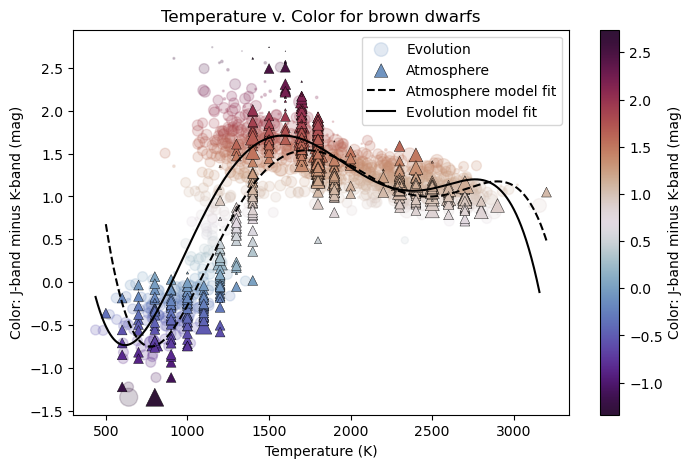

In [9]:
#--Scatter plot and curve fit for all data--
plt.figure(figsize=(8,5))
plt.scatter(all_evo, all_jk, s=all_age*20, alpha=0.2, c=all_jk,  cmap='twilight_shifted', marker='o', label='Evolution')
plt.scatter(all_atmo, all_jk, s=all_age*20, alpha=1, c=all_jk, edgecolor='k', linewidth=0.3, cmap='twilight_shifted', marker='^', label='Atmosphere')
plt.plot(all_atmo_sorted, quintic(all_atmo_sorted, allAtmoA, allAtmoB, allAtmoC, allAtmoD, allAtmoE, allAtmoF), color='black', linestyle='--', label='Atmosphere model fit')
plt.plot(all_evo_sorted, quintic(all_evo_sorted, allEvoA, allEvoB, allEvoC, allEvoD, allEvoE, allEvoF), color='black', label='Evolution model fit')
plt.title('Temperature v. Color for brown dwarfs')
plt.xlabel('Temperature (K)')
plt.ylabel('Color: J-band minus K-band (mag)')
plt.colorbar(label='Color: J-band minus K-band (mag)')
plt.legend()
plt.show()

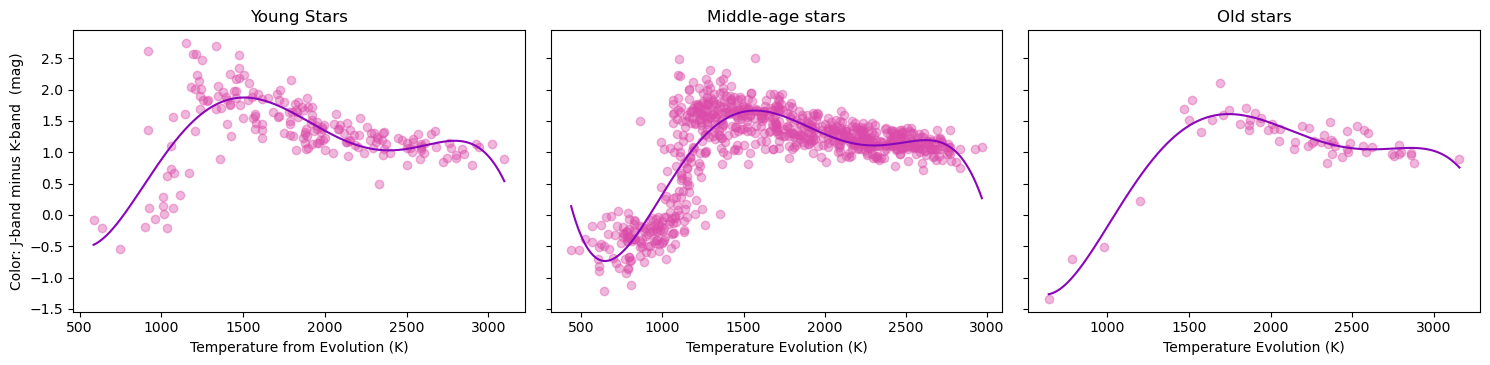

In [10]:
#--Scatter plot & curve fit for Evolution--
f, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 3.75), sharey=True)

#Young Stars
im1 = ax1.scatter(y_evo, y_jk, c='#db4ba9', alpha=0.4)
ax1.plot(y_evo_sorted, quintic(y_evo_sorted, yEvoA, yEvoB, yEvoC, yEvoD, yEvoE, yEvoF), color='#8a06ba')
ax1.set_title('Young Stars')
ax1.set_xlabel('Temperature from Evolution (K)')
ax1.set_ylabel('Color: J-band minus K-band  (mag)')

#Middle-aged stars
im2 = ax2.scatter(m_evo, m_jk, c='#db4ba9', alpha=0.4)
ax2.plot(m_evo_sorted, quintic(m_evo_sorted, mEvoA, mEvoB, mEvoC, mEvoD, mEvoE, mEvoF), color='#8a06ba')
ax2.set_title('Middle-age stars')
ax2.set_xlabel('Temperature Evolution (K)')

#Old stars
im3 = ax3.scatter(o_evo, o_jk, c='#db4ba9', alpha=0.4)
ax3.plot(o_evo_sorted, quintic(o_evo_sorted, oEvoA, oEvoB, oEvoC, oEvoD, oEvoE, oEvoF), color='#8a06ba')
ax3.set_title('Old stars')
ax3.set_xlabel('Temperature Evolution (K)')

plt.tight_layout()
plt.show()

In [11]:
#--printing out coefficients--
print("Evolution Equations")
print("Young stars:\nA:", yEvoA, "   B:", yEvoB, "   C:", yEvoC, "   D:", yEvoD, "   E:", yEvoE, "   F:", yEvoF)
print("Middle-age stars:\nA:", mEvoA, "   B:", mEvoB, "   C:", mEvoC, "   D:", mEvoD, "   E:", mEvoE, "   F:", mEvoF)
print("Old stars:\nA:", oEvoA, "   B:", oEvoB, "   C:", oEvoC, "   D:", oEvoD, "   E:", oEvoE, "   F:", oEvoF)
print("All:\nA:", allEvoA, "   B:", allEvoB, "   C:", allEvoC, "   D:", allEvoD, "   E:", allEvoE, "   F:", allEvoF)

Evolution Equations
Young stars:
A: 6.4670537037456555    B: -0.03375011705657794    C: 5.5892170422382904e-05    D: -3.781119586642055e-08    E: 1.1342641528203099e-11    F: -1.2558102402564452e-15
Middle-age stars:
A: 13.521752099811428    B: -0.060244092369512454    C: 9.029996153030778e-05    D: -5.879999345856415e-08    E: 1.751033287569814e-11    F: -1.9596641573732163e-15
Old stars:
A: 8.178285021468417    B: -0.03988771336897437    C: 5.818873704632343e-05    D: -3.5337869728800915e-08    E: 9.659439559229933e-12    F: -9.855311682293548e-16
All:
A: 10.314380112751213    B: -0.04785252822016976    C: 7.256192284564529e-05    D: -4.679694959832693e-08    E: 1.3651993914060471e-11    F: -1.486661330007634e-15


<Figure size 640x480 with 0 Axes>

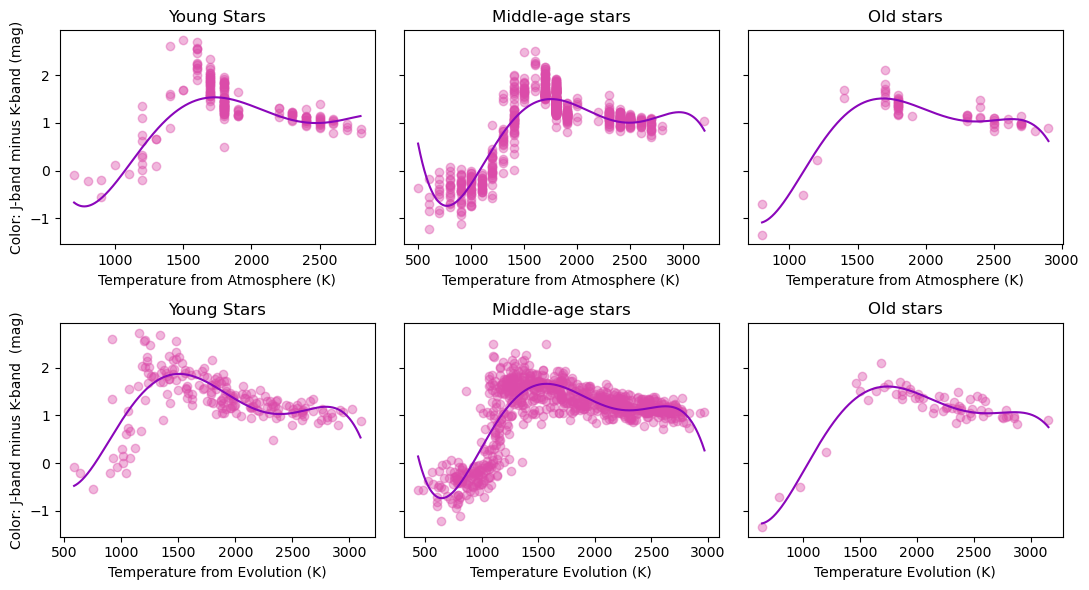

In [23]:
#--Scatter plot & curve fit for Atmosphere--
f, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(11, 6), sharey= True)

#Young Stars
im1 = ax1.scatter(y_atmo, y_jk, c='#db4ba9', alpha=0.4)
ax1.plot(y_atmo_sorted, quintic(y_atmo_sorted, allAtmoA, allAtmoB, allAtmoC, allAtmoD, allAtmoE, allAtmoF), color='#8a06ba')
ax1.set_title('Young Stars')
ax1.set_xlabel('Temperature from Atmosphere (K)')
ax1.set_ylabel('Color: J-band minus K-band (mag)')

#Middle-aged Stars
im2 = ax2.scatter(m_atmo, m_jk, c='#db4ba9', alpha=0.4)
ax2.plot(m_atmo_sorted, quintic(m_atmo_sorted, mAtmoA, mAtmoB, mAtmoC, mAtmoD, mAtmoE, mAtmoF), color='#8a06ba')
ax2.set_title('Middle-age stars')
ax2.set_xlabel('Temperature from Atmosphere (K)')
#ax2.set_ylabel('Color (mag)')

#Old Stars
im3 = ax3.scatter(o_atmo, o_jk, c='#db4ba9', alpha=0.4)
ax3.plot(o_atmo_sorted, quintic(o_atmo_sorted, oAtmoA, oAtmoB, oAtmoC, oAtmoD, oAtmoE, oAtmoF), color='#8a06ba')
ax3.set_title('Old stars')
ax3.set_xlabel('Temperature from Atmosphere (K)')
#ax3.set_ylabel('Color (mag)')

#Young Stars
im4 = ax4.scatter(y_evo, y_jk, c='#db4ba9', alpha=0.4)
ax4.plot(y_evo_sorted, quintic(y_evo_sorted, yEvoA, yEvoB, yEvoC, yEvoD, yEvoE, yEvoF), color='#8a06ba')
ax4.set_title('Young Stars')
ax4.set_xlabel('Temperature from Evolution (K)')
ax4.set_ylabel('Color: J-band minus K-band  (mag)')

#Middle-aged stars
im5 = ax5.scatter(m_evo, m_jk, c='#db4ba9', alpha=0.4)
ax5.plot(m_evo_sorted, quintic(m_evo_sorted, mEvoA, mEvoB, mEvoC, mEvoD, mEvoE, mEvoF), color='#8a06ba')
ax5.set_title('Middle-age stars')
ax5.set_xlabel('Temperature Evolution (K)')

#Old stars
im6 = ax6.scatter(o_evo, o_jk, c='#db4ba9', alpha=0.4)
ax6.plot(o_evo_sorted, quintic(o_evo_sorted, oEvoA, oEvoB, oEvoC, oEvoD, oEvoE, oEvoF), color='#8a06ba')
ax6.set_title('Old stars')
ax6.set_xlabel('Temperature Evolution (K)')

plt.tight_layout()
plt.show()

In [ ]:

plt.show()
#--printing out coefficients--
print("Atmospheric Equations")
print("Young stars:\nA:", yAtmoA, "   B:", yAtmoB, "   C:", yAtmoC, "   D:", yAtmoD, "   E:", yAtmoE, "   F:", yAtmoF)
print("Middle-age stars:\nA:", mAtmoA, "   B:", mAtmoB, "   C:", mAtmoC, "   D:", mAtmoD, "   E:", mAtmoE, "   F:", mAtmoF)
print("Old stars:\nA:", oAtmoA, "   B:", oAtmoB, "   C:", oAtmoC, "   D:", oAtmoD, "   E:", oAtmoE, "   F:", oAtmoF)
print("All:\nA:", allAtmoA, "   B:", allAtmoB, "   C:", allAtmoC, "   D:", allAtmoD, "   E:", allAtmoE, "   F:", allAtmoF)

Atmospheric Equations
Young stars:
A: 66.98542916531481    B: -0.23653412119161965    C: 0.00030849175948183315    D: -1.871057149000928e-07    E: 5.366899727492443e-11    F: -5.893124671330937e-15
Middle-age stars:
A: 17.707521588953867    B: -0.0668175382197341    C: 8.698734307807376e-05    D: -5.015671556943216e-08    E: 1.3336753157441322e-11    F: -1.3373125631820312e-15
Old stars:
A: 26.396918852690952    B: -0.10162686827247883    C: 0.00013651840618074125    D: -8.255379724591164e-08    E: 2.326825867296399e-11    F: -2.4937357518499685e-15
All:
A: 19.42823586135887    B: -0.07329345689915971    C: 9.593100907359916e-05    D: -5.581690045209042e-08    E: 1.500470566415132e-11    F: -1.5231571738009375e-15


In [ ]:
#Monte Carlo
def random_points(n):
  """Takes in an int value n, to determine the number of curve fits performed. Returns arrays for 5 Atmosphere coefficients in order first, and then returns 5 Evolution coefficients in order.
      Finds 300 random points from the middle-age group and finds a curve fit. Records the parameters for that curve and adds them to an array for each coefficient.
      Preforms n different curve fits."""
  #Empty lists
  a_atmo = []
  b_atmo = []
  c_atmo = []
  d_atmo = []
  e_atmo = []
  f_atmo = []
  a_evo = []
  b_evo = []
  c_evo = []
  d_evo = []
  e_evo = []
  f_evo = []

  for i in range(n): #performs the action n times
    atmo = []
    evo = []
    jk = []
    for i in range(300): #finds 300 points
      rand_num = random.randint(0, len(m_atmo)-1) #random index within the m_atmo group (doesn't matter if we use m_atmo or m_evo because they're both the same length)
      #Add point to place-holder list
      atmo.append(m_atmo[rand_num])
      evo.append(m_evo[rand_num])
      jk.append(m_jk[rand_num])

    #Creates a curve fit and records each coefficient into the appropriate list
    a_atmo.append(optimization.curve_fit(quintic, atmo, jk)[0][0])
    b_atmo.append(optimization.curve_fit(quintic, atmo, jk)[0][1])
    c_atmo.append(optimization.curve_fit(quintic, atmo, jk)[0][2])
    d_atmo.append(optimization.curve_fit(quintic, atmo, jk)[0][3])
    e_atmo.append(optimization.curve_fit(quintic, atmo, jk)[0][4])
    f_atmo.append(optimization.curve_fit(quintic, atmo, jk)[0][5])

    a_evo.append(optimization.curve_fit(quintic, evo, jk)[0][0])
    b_evo.append(optimization.curve_fit(quintic, evo, jk)[0][1])
    c_evo.append(optimization.curve_fit(quintic, evo, jk)[0][2])
    d_evo.append(optimization.curve_fit(quintic, evo, jk)[0][3])
    e_evo.append(optimization.curve_fit(quintic, evo, jk)[0][4])
    f_evo.append(optimization.curve_fit(quintic, evo, jk)[0][5])


  return a_atmo, b_atmo, c_atmo, d_atmo, e_atmo, f_atmo, a_evo, b_evo, c_evo, d_evo, e_evo, f_evo

a_atmo, b_atmo, c_atmo, d_atmo, e_atmo, f_evo, a_evo, b_evo, c_evo, d_evo, e_evo, f_atmo = random_points(1000)

<Figure size 640x480 with 0 Axes>

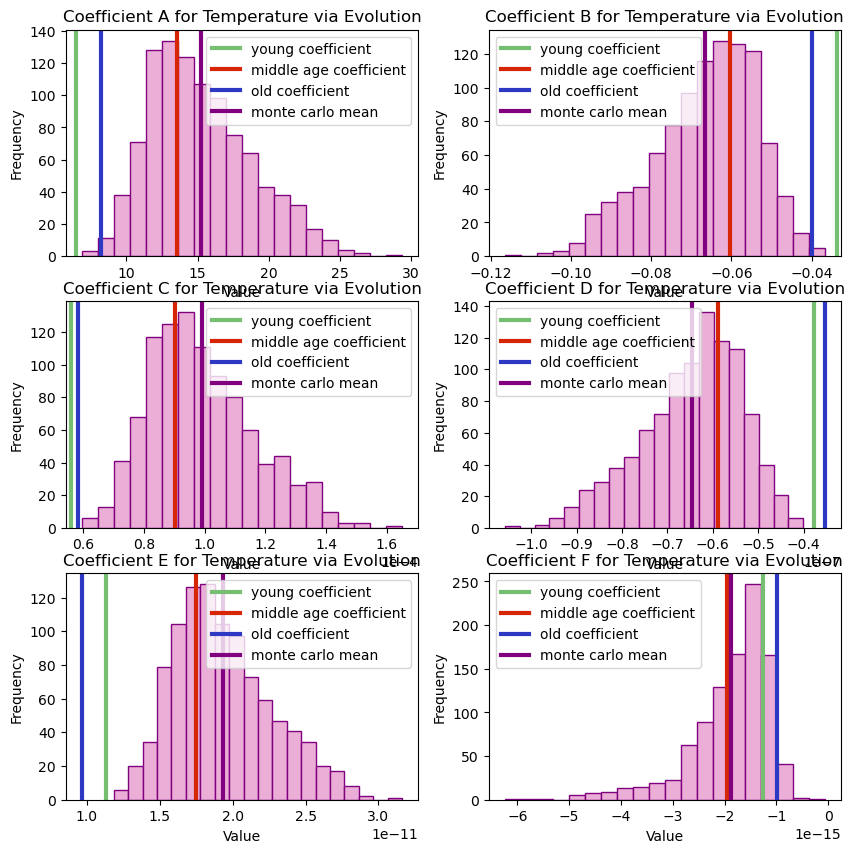

In [ ]:
#plotting coefficients for atmospheric  
f, ((ax1, ax2), (ax3, ax4), (ax5, ax6)) = plt.subplots(3, 2, figsize=(10,10))

ax1.hist(a_evo, edgecolor='purple', bins=20, color='#ebaed7')
ax1.axvline(yEvoA, linewidth=3, color='#76bf71', label='young coefficient')
ax1.axvline(mEvoA, linewidth=3, color='#d62606', label='middle age coefficient')
ax1.axvline(oEvoA, linewidth=3, color='#2d39c2', label='old coefficient')
ax1.axvline(np.mean(a_evo), linewidth=3, color='purple', label='monte carlo mean')
ax1.set_title('Coefficient A for Temperature via Evolution')
ax1.set_xlabel('Value')
ax1.set_ylabel('Frequency')
ax1.legend()

ax2.hist(b_evo, edgecolor='purple', bins=20, color='#ebaed7')
ax2.axvline(yEvoB, linewidth=3, color='#76bf71', label='young coefficient')
ax2.axvline(mEvoB, linewidth=3, color='#d62606', label='middle age coefficient')
ax2.axvline(oEvoB, linewidth=3, color='#2d39c2', label='old coefficient')
ax2.axvline(np.mean(b_evo), linewidth=3, color='purple', label='monte carlo mean')
ax2.set_title('Coefficient B for Temperature via Evolution')
ax2.set_xlabel('Value')
ax2.set_ylabel('Frequency')
ax2.legend()

ax3.hist(c_evo, edgecolor='purple', bins=20, color='#ebaed7')
ax3.axvline(yEvoC, linewidth=3, color='#76bf71', label='young coefficient')
ax3.axvline(mEvoC, linewidth=3, color='#d62606', label='middle age coefficient')
ax3.axvline(oEvoC, linewidth=3, color='#2d39c2', label='old coefficient')
ax3.axvline(np.mean(c_evo), linewidth=3, color='purple', label='monte carlo mean')
ax3.set_title('Coefficient C for Temperature via Evolution')
ax3.set_xlabel('Value')
ax3.set_ylabel('Frequency')
ax3.ticklabel_format(style='sci', axis='x', scilimits=(0, 0))
ax3.legend()

ax4.hist(d_evo, edgecolor='purple', bins=20, color='#ebaed7')
ax4.axvline(yEvoD, linewidth=3, color='#76bf71', label='young coefficient')
ax4.axvline(mEvoD, linewidth=3, color='#d62606', label='middle age coefficient')
ax4.axvline(oEvoD, linewidth=3, color='#2d39c2', label='old coefficient')
ax4.axvline(np.mean(d_evo), linewidth=3, color='purple', label='monte carlo mean')
ax4.set_title('Coefficient D for Temperature via Evolution')
ax4.set_xlabel('Value')
ax4.set_ylabel('Frequency')
ax4.legend()

ax5.hist(e_evo, edgecolor='purple', bins=20, color='#ebaed7')
ax5.axvline(yEvoE, linewidth=3, color='#76bf71', label='young coefficient')
ax5.axvline(mEvoE, linewidth=3, color='#d62606', label='middle age coefficient')
ax5.axvline(oEvoE, linewidth=3, color='#2d39c2', label='old coefficient')
ax5.axvline(np.mean(e_evo), linewidth=3, color='purple', label='monte carlo mean')
ax5.set_title('Coefficient E for Temperature via Evolution')
ax5.set_xlabel('Value')
ax5.set_ylabel('Frequency')
ax5.legend()

ax6.hist(f_evo, edgecolor='purple', bins=20, color='#ebaed7')
ax6.axvline(yEvoF, linewidth=3, color='#76bf71', label='young coefficient')
ax6.axvline(mEvoF, linewidth=3, color='#d62606', label='middle age coefficient')
ax6.axvline(oEvoF, linewidth=3, color='#2d39c2', label='old coefficient')
ax6.axvline(np.mean(f_evo), linewidth=3, color='purple', label='monte carlo mean')
ax6.set_title('Coefficient F for Temperature via Evolution')
ax6.set_xlabel('Value')
ax6.set_ylabel('Frequency')
ax6.legend()

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

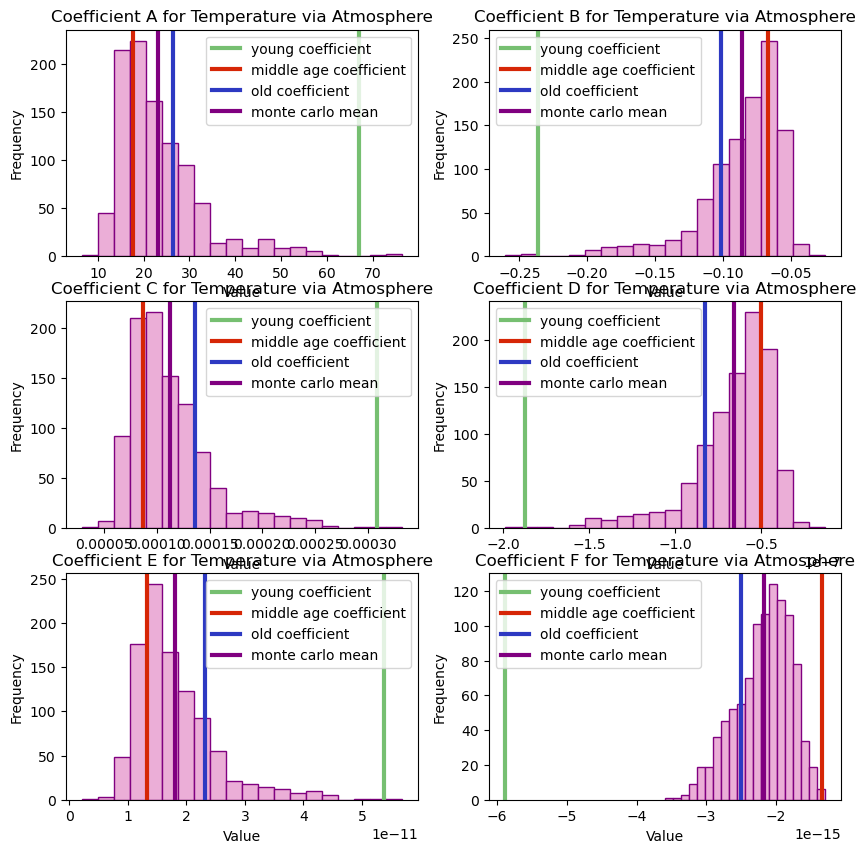

In [ ]:
#plotting coefficients for evolutionary 
f, ((ax1, ax2), (ax3, ax4), (ax5, ax6)) = plt.subplots(3, 2, figsize=(10,10))

ax1.hist(a_atmo, edgecolor='purple', bins=20, color='#ebaed7')
ax1.axvline(yAtmoA, linewidth=3, color='#76bf71', label='young coefficient')
ax1.axvline(mAtmoA, linewidth=3, color='#d62606', label='middle age coefficient')
ax1.axvline(oAtmoA, linewidth=3, color='#2d39c2', label='old coefficient')
ax1.axvline(np.mean(a_atmo), linewidth=3, color='purple', label='monte carlo mean')
ax1.set_title('Coefficient A for Temperature via Atmosphere')
ax1.set_xlabel('Value')
ax1.set_ylabel('Frequency')
ax1.legend()

ax2.hist(b_atmo, edgecolor='purple', bins=20, color='#ebaed7')
ax2.axvline(yAtmoB, linewidth=3, color='#76bf71', label='young coefficient')
ax2.axvline(mAtmoB, linewidth=3, color='#d62606', label='middle age coefficient')
ax2.axvline(oAtmoB, linewidth=3, color='#2d39c2', label='old coefficient')
ax2.axvline(np.mean(b_atmo), linewidth=3, color='purple', label='monte carlo mean')
ax2.set_title('Coefficient B for Temperature via Atmosphere')
ax2.set_xlabel('Value')
ax2.set_ylabel('Frequency')
ax2.legend()

ax3.hist(c_atmo, edgecolor='purple', bins=20, color='#ebaed7')
ax3.axvline(yAtmoC, linewidth=3, color='#76bf71', label='young coefficient')
ax3.axvline(mAtmoC, linewidth=3, color='#d62606', label='middle age coefficient')
ax3.axvline(oAtmoC, linewidth=3, color='#2d39c2', label='old coefficient')
ax3.axvline(np.mean(c_atmo), linewidth=3, color='purple', label='monte carlo mean')
ax3.set_title('Coefficient C for Temperature via Atmosphere')
ax3.set_xlabel('Value')
ax3.set_ylabel('Frequency')
ax3.legend()

ax4.hist(d_atmo, edgecolor='purple', bins=20, color='#ebaed7')
ax4.axvline(yAtmoD, linewidth=3, color='#76bf71', label='young coefficient')
ax4.axvline(mAtmoD, linewidth=3, color='#d62606', label='middle age coefficient')
ax4.axvline(oAtmoD, linewidth=3, color='#2d39c2', label='old coefficient')
ax4.axvline(np.mean(d_atmo), linewidth=3, color='purple', label='monte carlo mean')
ax4.set_title('Coefficient D for Temperature via Atmosphere')
ax4.set_xlabel('Value')
ax4.set_ylabel('Frequency')
ax4.legend()

ax5.hist(e_atmo, edgecolor='purple', bins=20, color='#ebaed7')
ax5.axvline(yAtmoE, linewidth=3, color='#76bf71', label='young coefficient')
ax5.axvline(mAtmoE, linewidth=3, color='#d62606', label='middle age coefficient')
ax5.axvline(oAtmoE, linewidth=3, color='#2d39c2', label='old coefficient')
ax5.axvline(np.mean(e_atmo), linewidth=3, color='purple', label='monte carlo mean')
ax5.set_title('Coefficient E for Temperature via Atmosphere')
ax5.set_xlabel('Value')
ax5.set_ylabel('Frequency')
ax5.legend()

ax6.hist(f_atmo, edgecolor='purple', bins=20, color='#ebaed7')
ax6.axvline(yAtmoF, linewidth=3, color='#76bf71', label='young coefficient')
ax6.axvline(mAtmoF, linewidth=3, color='#d62606', label='middle age coefficient')
ax6.axvline(oAtmoF, linewidth=3, color='#2d39c2', label='old coefficient')
ax6.axvline(np.mean(f_atmo), linewidth=3, color='purple', label='monte carlo mean')
ax6.set_title('Coefficient F for Temperature via Atmosphere')
ax6.set_xlabel('Value')
ax6.set_ylabel('Frequency')
ax6.legend()

plt.tight_layout()
plt.show()

In [17]:
def z_score(x, u, o):
  """Finds the z-score of an input value x, in a data set with mean u and standard devation o. Returns the z score as a float"""
  z = (x-u)/o
  return z

In [18]:
##--Evolution Statistics--

#Means
a_evo_mean = np.mean(a_evo)
b_evo_mean = np.mean(b_evo)
c_evo_mean = np.mean(c_evo)
d_evo_mean = np.mean(d_evo)
e_evo_mean = np.mean(e_evo)
f_evo_mean = np.mean(f_evo)
#Standard Deviations
a_evo_std = np.std(a_evo)
b_evo_std = np.std(b_evo)
c_evo_std = np.std(c_evo)
d_evo_std = np.std(d_evo)
e_evo_std = np.std(e_evo)
f_evo_std = np.std(f_evo)
#Z-Scores
#Young age group
z_ay_evo = z_score(yEvoA, a_evo_mean, a_evo_std)
z_by_evo = z_score(yEvoB, b_evo_mean, b_evo_std)
z_cy_evo = z_score(yEvoC, c_evo_mean, c_evo_std)
z_dy_evo = z_score(yEvoD, d_evo_mean, d_evo_std)
z_ey_evo = z_score(yEvoE, e_evo_mean, e_evo_std)
z_fy_evo = z_score(yEvoF, f_evo_mean, f_evo_std)
av_zy_evo = (abs(z_ay_evo)+abs(z_by_evo)+abs(z_cy_evo)+abs(z_dy_evo)+abs(z_ey_evo)+abs(z_fy_evo))/6
#Middle-age group
z_am_evo = z_score(mEvoA, a_evo_mean, a_evo_std)
z_bm_evo = z_score(mEvoB, b_evo_mean, b_evo_std)
z_cm_evo = z_score(mEvoC, c_evo_mean, c_evo_std)
z_dm_evo = z_score(mEvoD, d_evo_mean, d_evo_std)
z_em_evo = z_score(mEvoE, e_evo_mean, e_evo_std)
z_fm_evo = z_score(mEvoF, f_evo_mean, f_evo_std)
av_zm_evo = (abs(z_am_evo)+abs(z_bm_evo)+abs(z_cm_evo)+abs(z_dm_evo)+abs(z_em_evo)+abs(z_fm_evo))/6
#Old age group
z_ao_evo = z_score(oEvoA, a_evo_mean, a_evo_std)
z_bo_evo = z_score(oEvoB, b_evo_mean, b_evo_std)
z_co_evo = z_score(oEvoC, c_evo_mean, c_evo_std)
z_do_evo = z_score(oEvoD, d_evo_mean, d_evo_std)
z_eo_evo = z_score(oEvoE, e_evo_mean, e_evo_std)
z_fo_evo = z_score(oEvoF, f_evo_mean, f_evo_std)
av_zo_evo = (abs(z_ao_evo)+abs(z_bo_evo)+abs(z_co_evo)+abs(z_do_evo)+abs(z_eo_evo)+abs(z_fo_evo))/6
#Average Z-score of all age groups:
av_all_evo = (av_zy_evo+av_zm_evo+av_zo_evo)/3

In [19]:
#--Atmosphere Statistics--

#Means
a_atmo_mean = np.mean(a_atmo)
b_atmo_mean = np.mean(b_atmo)
c_atmo_mean = np.mean(c_atmo)
d_atmo_mean = np.mean(d_atmo)
e_atmo_mean = np.mean(e_atmo)
f_atmo_mean = np.mean(f_atmo)
#Standard Deviations
a_atmo_std = np.std(a_atmo)
b_atmo_std = np.std(b_atmo)
c_atmo_std = np.std(c_atmo)
d_atmo_std = np.std(d_atmo)
e_atmo_std = np.std(e_atmo)
f_atmo_std = np.std(f_atmo)
#Z-Scores
#Young age group
z_ay_atmo = z_score(yAtmoA, a_atmo_mean, a_atmo_std)
z_by_atmo = z_score(yAtmoB, b_atmo_mean, b_atmo_std)
z_cy_atmo = z_score(yAtmoC, c_atmo_mean, c_atmo_std)
z_dy_atmo = z_score(yAtmoD, d_atmo_mean, d_atmo_std)
z_ey_atmo = z_score(yAtmoE, e_atmo_mean, e_atmo_std)
z_fy_atmo = z_score(yAtmoF, f_atmo_mean, f_atmo_std)
av_zy_atmo = (abs(z_ay_atmo)+abs(z_by_atmo)+abs(z_cy_atmo)+abs(z_dy_atmo)+abs(z_ey_atmo)+abs(z_fy_atmo))/6
#Middle-age group
z_am_atmo = z_score(mAtmoA, a_atmo_mean, a_atmo_std)
z_bm_atmo = z_score(mAtmoB, b_atmo_mean, b_atmo_std)
z_cm_atmo = z_score(mAtmoC, c_atmo_mean, c_atmo_std)
z_dm_atmo = z_score(mAtmoD, d_atmo_mean, d_atmo_std)
z_em_atmo = z_score(mAtmoE, e_atmo_mean, e_atmo_std)
z_fm_atmo = z_score(mAtmoF, f_atmo_mean, f_atmo_std)
av_zm_atmo = (abs(z_am_atmo)+abs(z_bm_atmo)+abs(z_cm_atmo)+abs(z_dm_atmo)+abs(z_em_atmo)+abs(z_fm_atmo))/6
#Old age group
z_ao_atmo = z_score(oAtmoA, a_atmo_mean, a_atmo_std)
z_bo_atmo = z_score(oAtmoB, b_atmo_mean, b_atmo_std)
z_co_atmo = z_score(oAtmoC, c_atmo_mean, c_atmo_std)
z_do_atmo = z_score(oAtmoD, d_atmo_mean, d_atmo_std)
z_eo_atmo = z_score(oAtmoE, e_atmo_mean, e_atmo_std)
z_fo_atmo = z_score(oAtmoF, f_atmo_mean, f_atmo_std)
av_zo_atmo = (abs(z_ao_atmo)+abs(z_bo_atmo)+abs(z_co_atmo)+abs(z_do_atmo)+abs(z_eo_atmo)+abs(z_fo_atmo))/6
#Average Z-score of all age groups:
av_all_atmo = (av_zy_atmo+av_zm_atmo+av_zo_atmo)/3

In [20]:
print("Evolution Stats:")
print("Middle-aged group coefficients:\nA", mEvoA, "   B:", mEvoB, "   C:", mEvoC, "   D:", mEvoD, "   E:", mEvoE, "   F:", mEvoF)
print("Monte Carlo Means:\nA:", a_evo_mean, "   B:", b_evo_mean, "   C:", c_evo_mean, "   D:", d_evo_mean, "   E:", e_evo_mean, "   F:", f_evo_mean)
print("Monte Carlo Standard Deviations:\nA:", a_evo_std, "   B:", b_evo_std, "   C:", c_evo_std, "   D:", d_evo_std, "   E:", e_evo_std, "   F:", f_evo_std)
print("Z-Scores for young age group:\nA:", z_ay_evo, "   B:", z_by_evo, "   C:", z_cy_evo, "   D:", z_dy_evo, "   E:", z_ey_evo, "   F:", z_fy_evo)
print("Z-Scores for middle-age group:\nA:", z_am_evo, "   B:", z_bm_evo, "   C:", z_cm_evo, "   D:", z_dm_evo, "   E:", z_em_evo, "   F:", z_fm_evo)
print("Z-Scores for old age group:\nA:", z_ao_evo, "   B:", z_bo_evo, "   C:", z_co_evo, "   D:", z_do_evo, "   E:", z_eo_evo, "   F:", z_fo_evo)
print("Average Z-score:\nYoung:", av_zy_evo, "   Middle-age:", av_zm_evo, "   Old:", av_zo_evo)
print("Average z-score between all age groups:", av_all_evo)
print("\n=======================\n")
print("Atmosphere Stats:")
print("Middle-aged group coefficients:\nA", mAtmoA, "   B:", mAtmoB, "   C:", mAtmoC, "   D:", mAtmoD, "   E:", mAtmoE, "   F:", mAtmoF)
print("Monte Carlo Means:\nA:", a_atmo_mean, "   B:", b_atmo_mean, "   C:", c_atmo_mean, "   D:", d_atmo_mean, "   E:", e_atmo_mean, "   F:", f_atmo_mean)
print("Z-Scores for young age group:\nA:", z_ay_atmo, "   B:", z_by_atmo, "   C:", z_cy_atmo, "   D:", z_dy_atmo, "   E:", z_ey_atmo, "   F:", z_fy_atmo)
print("Z-Scores for middle-age group:\nA:", z_am_atmo, "   B:", z_bm_atmo, "   C:", z_cm_atmo, "   D:", z_dm_atmo, "   E:", z_em_atmo, "   F:", z_fm_atmo)
print("Z-Scores for old age group:\nA:", z_ao_atmo, "   B:", z_bo_atmo, "   C:", z_co_atmo, "   D:", z_do_atmo, "   E:", z_eo_atmo, "   F:", z_fo_atmo)
print("Average Z-score:\nYoung:", av_zy_atmo, "   Middle-age:", av_zm_atmo, "   Old:", av_zo_atmo)
print("Average z-score between all age groups:", av_all_atmo)

Evolution Stats:
Middle-aged group coefficients:
A 13.521752099811428    B: -0.060244092369512454    C: 9.029996153030778e-05    D: -5.879999345856415e-08    E: 1.751033287569814e-11    F: -1.9596641573732163e-15
Monte Carlo Means:
A: 15.22673393174841    B: -0.06654944046602146    C: 9.90550482274108e-05    D: -6.454662196546826e-08    E: 1.9304972449910125e-11    F: -1.880953847857572e-15
Monte Carlo Standard Deviations:
A: 3.6084649112057923    B: 0.01286159566632022    C: 1.7289236311881603e-05    D: 1.1051335627565435e-08    E: 3.380382335246356e-12    F: 7.82930561682123e-16
Z-Scores for young age group:
A: -2.4275364853348815    B: 2.5501752862075167    C: -2.4965173143804664    D: 2.4192031624088335    E: -2.3554527660039812    F: 0.7984662219060762
Z-Scores for middle-age group:
A: -0.47249505645525336    B: 0.4902461762983568    C: -0.5063894401793967    D: 0.5199940261130295    E: -0.5308984003080811    F: -0.10053293787195555
Z-Scores for old age group:
A: -1.95330953292398